In [ ]:
!pip install transformers

In [ ]:
!pip install transformers datasets torch scikit-learn pandas numpy matplotlib seaborn ipykernel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 44.4 MB/s eta 0:00:00


In [ ]:
!pip install kagglehub

In [ ]:
from transformers import Trainer, RobertaForSequenceClassification, RobertaTokenizer, TrainingArguments
import torch
from torch.utils.data import Dataset
import pandas as pd
from sklearn.model_selection import train_test_split
import re
import os
import kagglehub

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer


path = kagglehub.dataset_download("tleonel/cost-of-living")


df = pd.read_csv(os.path.join(path, 'costofliving-query-tweets.csv'))

Using Colab cache for faster access to the 'cost-of-living' dataset.


In [ ]:
!pip install vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 12.4 MB/s eta 0:00:00


In [ ]:
!pip install emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 28.5 MB/s eta 0:00:00


In [ ]:
import re
import emoji
from bs4 import BeautifulSoup

def preprocess_text(text):
    text = BeautifulSoup(text, "html.parser").get_text()
    text = emoji.replace_emoji(text, replace="")
    text = text.lower()
    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", '', text, flags=re.MULTILINE)
    # Remove mentions, hashtags special characters
    text = re.sub(r'\@\w+|\#','', text)
    text = re.sub(r"[^a-zA-Z\s]", '', text)
    return text.strip()

df['clean_text'] = df['tweet_text'].astype(str).apply(preprocess_text)
display(df.head())

,date_time,username,user_location,user_description,verified,followers_count,following_count,tweet_like_count,tweet_retweet_count,tweet_reply_count,source,tweet_text,clean_text
0,2022-09-09 00:19:49+00:00,Beer_Enjoyer420,"District of Columbia, USA","I like news, weather, and sports updates! (And...",False,87,270,0,0,0,"<a href=""http://twitter.com/download/android"" ...","""UPS affects virtually every American and here...",ups affects virtually every american and heres...
1,2022-09-09 00:19:48+00:00,MLAIrfanSabir,"Calgary, Treaty 7 Territory","The official account of MLA Irfan Sabir, JSS C...",True,7432,854,0,0,0,"<a href=""http://twitter.com/download/iphone"" r...",The UCP is not capable of giving Albertans a c...,the ucp is not capable of giving albertans a c...
2,2022-09-09 00:19:04+00:00,AFDJnews,Australia,ADFJ is your top Australian farming industry n...,False,26,77,0,0,0,"<a href=""https://help.twitter.com/en/using-twi...",Cost of living pushed up by climate-driven flo...,cost of living pushed up by climatedriven floo...
3,2022-09-09 00:18:51+00:00,LitmusTree,Yah Dads House,🇹🇼You looked through my profile after you saw ...,False,56,251,0,0,0,"<a href=""http://twitter.com/download/iphone"" r...",@IIPatricio_ @Askechadd @emexdizzy @twinkbride...,i could not have a higher cost cost of living ...
4,2022-09-09 00:18:23+00:00,athenastits,they/them | 18 | uk | leftist,if it's not our flag means death it's the old ...,False,52,154,0,0,0,"<a href=""http://twitter.com/download/android"" ...",there's a massive cost of living crisis in the...,theres a massive cost of living crisis in the ...


In [ ]:
uk_keywords = ('uk', 'united kingdom', 'england', 'scotland', 'wales', 'northern ireland', 'london', 'manchester', 'birmingham')

def is_uk(text):
    return any(kw in text for kw in uk_keywords)

df = df[df['clean_text'].apply(is_uk)]

In [ ]:
analyzer = SentimentIntensityAnalyzer()

def vader_sentiment_label(text):
    score = analyzer.polarity_scores(text)['compound']
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

df['sentiment'] = df['clean_text'].apply(vader_sentiment_label)

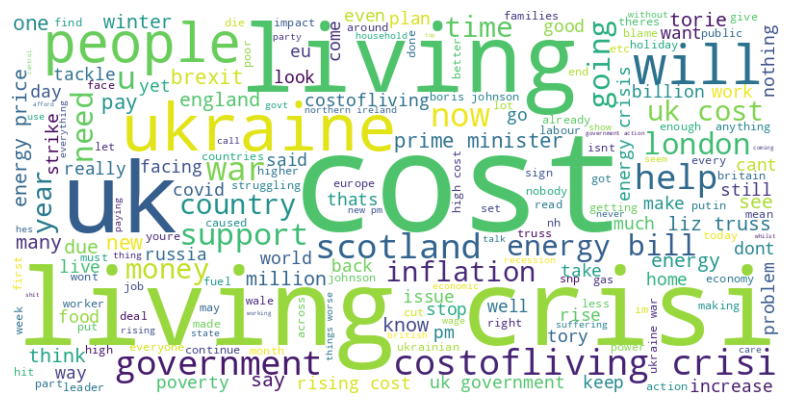

In [ ]:
!pip install wordcloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

all_text = "".join(df['clean_text'])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [ ]:
label2id = {'negative': 0, 'neutral': 1, 'positive': 2}
id2label = {0: 'negative', 1: 'neutral', 2: 'positive'}

df['label'] = df['sentiment'].map(label2id)

In [ ]:
train_texts, val_texts, train_labels, val_labels = train_test_split(
df['clean_text'].tolist(),
df['label'].tolist(),
test_size=0.2,
random_state=42,
stratify=df['label']
)

In [ ]:
model = RobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=3)
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    warmup_steps=100,
    weight_decay=0.01,
    logging_dir='./logs',
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
def compute_metrics(pred):
  labels = pred.label_ids
  preds = pred.predictions.argmax(-1)
  acc = accuracy_score(labels, preds)
  precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
  return {
      'accuracy': acc,
      'f1': f1,
      'precision': precision,
      'recall': recall
  }

In [ ]:
from torch.utils.data import Dataset

class TweetDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            return_token_type_ids=False,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt',
            truncation=True,
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

train_dataset = TweetDataset(train_texts, train_labels, tokenizer)
eval_dataset = TweetDataset(val_texts, val_labels, tokenizer)

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [ ]:
from transformers import Trainer, RobertaForSequenceClassification, RobertaTokenizer, TrainingArguments, DataCollatorWithPadding
import torch
from torch.utils.data import Dataset
import pandas as pd
from sklearn.model_selection import train_test_split
import re
import os
import kagglehub

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
    data_collator=data_collator
)

In [ ]:
trainer.train()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: abdullah26musa (abdullah26musa-shellshift) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.345300,0.352179,0.879538,0.875626,0.879705,0.879538
2,0.356200,0.332757,0.898677,0.895366,0.896166,0.898677


TrainOutput(global_step=1776, training_loss=0.3910923371980856, metrics={'train_runtime': 826.5184, 'train_samples_per_second': 34.38, 'train_steps_per_second': 2.149, 'total_flos': 1869157719539712.0, 'train_loss': 0.3910923371980856, 'epoch': 2.0})

In [ ]:
eval_matrices = {}
for log_entry in trainer.state.log_history:
  if 'eval_accuracy' in log_entry:
    eval_matrices['accuracy'] = log_entry.get('eval_accuracy')
    eval_matrices['f1'] = log_entry.get('eval_f1')
    eval_matrices['precision'] = log_entry.get('eval_precision')
    eval_matrices['recall'] = log_entry.get('eval_recall')

    display(eval_matrices)

{'accuracy': 0.8795384182381086,
 'f1': 0.8756261268302199,
 'precision': 0.8797045866806819,
 'recall': 0.8795384182381086}

{'accuracy': 0.8986771742189699,
 'f1': 0.8953657553487719,
 'precision': 0.8961657526784773,
 'recall': 0.8986771742189699}

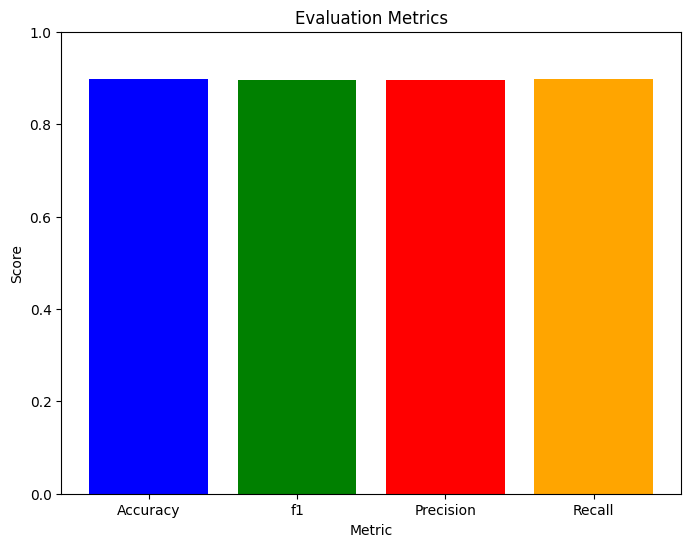

In [ ]:
import matplotlib.pyplot as plt

metrics_names = ['Accuracy', 'f1', 'Precision', 'Recall']
metric_values = [eval_matrices['accuracy'], eval_matrices['f1'], eval_matrices['precision'], eval_matrices['recall']]

plt.figure(figsize=(8, 6))
plt.bar(metrics_names, metric_values, color=['blue', 'green', 'red', 'orange'])
plt.title('Evaluation Metrics')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.show()

In [ ]:
# Load the original data again to access the unlearned tweet_text
original_df = pd.read_csv(os.path.join(path, 'costofliving-query-tweets.csv'))

# Filter the original data to keep only Uk-based tweets
original_uk_df = original_df[original_df['tweet_text'].astype(str).apply(is_uk)]

# Identify tweets containing emojis
emoji_pattern = re.compile(r"["
        u'\U0001F600-\U0001F64F'  # emoticons
        u'\U0001F300-\U0001F5FF'  # symbols & pictographs
        u'\U0001F1E0-\U0001F1FF' # flags (iOS)
        u'\U00002702-\U000027B0'
        u'\U000024C2-\U0001F251'
        u'\U0001f900-\U0001f9ff' # Supplemental Symbols and Pictographs
        u'\U0001f680-\U0001f6ff' # Transport and Map
        u'\U0001f600-\U0001f64f' # Emoticons
        u'\U0001f300-\U0001f5ff' # Geometric Shapes
        u'\U0001f500-\U0001f5ff' # Miscellaneous Symbols
        u'\U0001f400-\U0001f4ff' # Glyphs
        u'\U0001f300-\U0001f5ff' # Additional symbols
        u'\U0001f200-\U0001f2ff' # Enclosed Ideographic Supplement
        u'\U00002500-\U0000257F' # Box Drawing
        u'\U00002580-\U0000259F' # Block Elements
        u'\U000025A0-\U000025FF' # Geometric Shapes
        u'\U00002600-\U000026FF' # Miscellaneous Symbols
        u'\U00002700-\U000027BF' # Dingbats
        u'\U00002300-\U000023FF' # Miscellaneous Technical
        u'\U00002B50' # Star
        u'\U0001F900-\U0001F9FF' # Supplemental Symbols and Pictographs
        u'\U0001FA70-\U0001FAFF' # Symbols and Pictographs Extended-A
        u'\U0000200D' # Zero Width Joiner
        u'\u200d' # Zero Width Joiner
        u'\u231a-\u231b' # Watch, Hourglass
        u'\u23e9-\u23ec' # Fast Forward, Rewind
        u'\u23f0' # Alarm Clock
        u'\u23f3' # Hourglass with Flowing Sand
        u'\u24c2' # Circled M
        u'\u25aa-\u25ab' # Small Squares
        u'\u25fb-\u25fe' # Medium Squares
        u'\u2600-\u2601' # Sun, Cloud
        u'\u260e' # Telephone
        u'\u2611' # Ballot Box with Check
        u'\u2614-\u2615' # Umbrella, Hot Beverage
        u'\u2618' # Shamrock
        u'\u261d' # Index Pointing Up
        u'\u2620' # Skull and Crossbones
        u'\u2622-\u2623' # Radioactive, Biohazard
        u'\u2626' # Caduceus
        u'\u262a' # Star and Crescent
        u'\u262e-\u262f' # Peace, Yin Yang
        u'\u2638-\u263a' # Wheel of Dharma, Frowny Face, Smiley Face
        u'\u2648-\u2653' # Zodiac Signs
        u'\u265f-\u2660' # Spades, Clubs
        u'\u2663-\u2666' # Diamonds, Hearts
        u'\u2668' # Hot Springs
        u'\u267b' # Recyling Symbol
        u'\u267f' # Wheelchair Symbol
        u'\u2692-\u2694' # Hammer and Pick, Anchor, Crossed Swords
        u'\u2696-\u2697' # Scales, Alembic
        u'\u2699' # Gear
        u'\u269b-\u269c' # Atom Symbol, Fleur-de-Lis
        u'\u26a0-\u26a1' # Warning, High Voltage
        u'\u26aa-\u26ab' # Medium Circles
        u'\u26b0-\u26b1' # Coffin, Funeral Urn
        u'\u26bd-\u26be' # Soccer Ball, Baseball
        u'\u26c4-\u26c5' # Snowman, Sun Behind Cloud
        u'\u26c8' # Thunder Cloud and Rain
        u'\u26cf-\u26d1' # Pick, Helmet with Cross, Shield
        u'\u26d3-\u26d4' # Chains, No Entry
        u'\u26e9-\u26ea' # Shinto Shrine, Church
        u'\u26f0-\u26f1' # Mountain, Umbrella on Ground
        u'\u26f2-\u26f3' # Fountain, Flag in Hole
        u'\u26f4-\u26f5' # Ferry, Sailboat
        u'\u26f7-\u26fa' # Skier, Sled, Ice Skate, Tent
        u'\u26fd' # Fuel Pump
        u'\u2705' # White Heavy Check Mark
        u'\u2708-\u2709' # Airplane, Envelope
        u'\u270a-\u270b' # Raised Fist, Raised Hand
        u'\u270c-\u270d' # Victory Hand, Writing Hand
        u'\u270f' # Pencil
        u'\u2712' # Black Nib
        u'\u2714' # Heavy Check Mark
        u'\u2716' # Heavy Multiplication X
        u'\u271d' # Latin Cross
        u'\u2721' # Star of David
        u'\u2728' # Sparkles
        u'\u2733-\u2734' # Eight Pointed Star, Eight Spoked Asterisk
        u'\u2744' # Snowflake
        u'\u2747' # Sparkle
        u'\u274c' # Cross Mark
        u'\u274e' # Negative Squared Cross Mark
        u'\u2753-\u2755' # Question Marks
        u'\u2757' # Exclamation Mark
        u'\u2763-\u2764' # Heavy Heart Exclamation, Heavy Black Heart
        u'\u2795-\u2797' # Plus, Minus, Divide
        u'\u27a1' # Right Arrow
        u'\u27b0' # Curly Loop
        u'\u27bf' # Double Curly Loop
        u'\u2934-\u2935' # Arrows
        u'\u2b05-\u2b07' # Arrows
        u'\u2b1b-\u2b1c' # Squares
        u'\u2b50' # Star
        u'\u2b55' # Circle
        u'\u3030' # Wavy Dash
        u'\u303d' # Part Alternation Mark
        u'\u3297' # Circled Ideograph Congratulation
        u'\u3299' # Circled Ideograph Secret
        u'\U0001F000-\U0001F02F' # Mahjong Tiles
        u'\U0001F0AA' # Playing Cards
        u'\U0001F100-\U0001F16F' # Enclosed Alphanumeric Supplement
        u'\U0001F170-\U0001F19F' # Enclosed Ideographic Supplement
        u'\U0001F1E6-\U0001F1FF' # Regional Indicator Symbols
        u'\U0001F200-\U0001F25F' # Enclosed Ideographic Supplement
        u'\U0001F300-\U0001F5FF' # Miscellaneous Symbols and Pictographs
        u'\U0001F600-\U0001F64F' # Emoticons
        u'\U0001F680-\U0001F6FF' # Transport and Map
        u'\U0001F700-\U0001F77F' # Alchemical Symbols
        u'\U0001F780-\U0001F7FF' # Geometric Shapes Extended
        u'\U0001F800-\U0001F8FF' # Supplemental Arrows-C
        u'\U0001F900-\U0001F9FF' # Supplemental Symbols and Pictographs
        u'\U0001FA00-\U0001FA6F' # Chess Symbols
        u'\U0001FA70-\U0001FAFF' # Symbols and Pictographs Extended-A
        u'\U00002702-\U000027B0' # Dingbats
        u'\U000024C2-\U0001F251' # Enclosed Alphanumeric Supplement
        u'\U0001F3FB-\U0001F3FF' # Skin Tone Modifiers
        u'\u200d'  # Zero Width Joiner
        u'\ufe0f' # Variation Selector-16
        "]+", flags=re.UNICODE)

tweets_with_emojis_df = original_uk_df[original_uk_df['tweet_text'].astype(str).apply(lambda x: bool(emoji_pattern.search(x)))]
display(tweets_with_emojis_df.head())

,date_time,username,user_location,user_description,verified,followers_count,following_count,tweet_like_count,tweet_retweet_count,tweet_reply_count,source,tweet_text
354,2022-09-08 22:37:27+00:00,GavittEmma,London/UK,We're all in this together. Just gotta take it...,False,1,29,3,1,0,"<a href=""http://twitter.com/download/android"" ...",@jmcaree @judeinlondon2 @roflcopterftw In the ...
722,2022-09-08 21:26:49+00:00,bealittIebraver,ꪶ ֯ 𓏲ꪆ ៸៸ ꫂ⠀⠀⠀you are the 𝓼pitting ...,⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀₍...,False,498,216,4,0,0,"<a href=""http://twitter.com/download/android"" ...",┆͙ i promise you while im worrying about wheth...
723,2022-09-08 21:26:48+00:00,jayneyadumim,The Dales,“Liberals are very broadminded. They are alway...,False,25,33,0,0,0,"<a href=""http://twitter.com/download/iphone"" r...",@LukeAlisonnn @EFL_Comms Cost of living crisis...
862,2022-09-08 21:06:21+00:00,ellengellenger,scotland,"she/they✨life is short, but i am shorter",False,297,592,2,0,0,"<a href=""http://twitter.com/download/iphone"" r...","@_ivorytowers lol we hate the monarchy, we’re ..."
996,2022-09-08 20:46:03+00:00,red___square,NaN,"Software bloke, Manchester-UK. Using Clickhous...",False,1011,3450,61,0,2,"<a href=""http://twitter.com/download/android"" ...",@LukeAlisonnn @EFL_Comms mentioning the cost o...


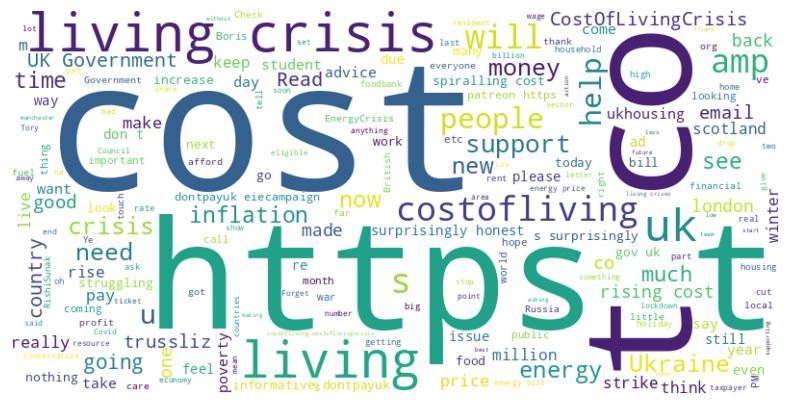

In [ ]:
!pip install wordcloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

all_text_emoji = " ".join(tweets_with_emojis_df['tweet_text'])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_text_emoji)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [ ]:
tweets_with_emojis_df['sentiment'] = tweets_with_emojis_df['tweet_text'].astype(str).apply(vader_sentiment_label)
tweets_with_emojis_df['label'] = tweets_with_emojis_df['sentiment'].map(label2id)
display(tweets_with_emojis_df.head())

/tmp/ipython-input-3470956178.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tweets_with_emojis_df['sentiment'] = tweets_with_emojis_df['tweet_text'].astype(str).apply(vader_sentiment_label)
/tmp/ipython-input-3470956178.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tweets_with_emojis_df['label'] = tweets_with_emojis_df['sentiment'].map(label2id)


,date_time,username,user_location,user_description,verified,followers_count,following_count,tweet_like_count,tweet_retweet_count,tweet_reply_count,source,tweet_text,sentiment,label
354,2022-09-08 22:37:27+00:00,GavittEmma,London/UK,We're all in this together. Just gotta take it...,False,1,29,3,1,0,"<a href=""http://twitter.com/download/android"" ...",@jmcaree @judeinlondon2 @roflcopterftw In the ...,negative,0
722,2022-09-08 21:26:49+00:00,bealittIebraver,ꪶ ֯ 𓏲ꪆ ៸៸ ꫂ⠀⠀⠀you are the 𝓼pitting ...,⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀₍...,False,498,216,4,0,0,"<a href=""http://twitter.com/download/android"" ...",┆͙ i promise you while im worrying about wheth...,negative,0
723,2022-09-08 21:26:48+00:00,jayneyadumim,The Dales,“Liberals are very broadminded. They are alway...,False,25,33,0,0,0,"<a href=""http://twitter.com/download/iphone"" r...",@LukeAlisonnn @EFL_Comms Cost of living crisis...,negative,0
862,2022-09-08 21:06:21+00:00,ellengellenger,scotland,"she/they✨life is short, but i am shorter",False,297,592,2,0,0,"<a href=""http://twitter.com/download/iphone"" r...","@_ivorytowers lol we hate the monarchy, we’re ...",negative,0
996,2022-09-08 20:46:03+00:00,red___square,NaN,"Software bloke, Manchester-UK. Using Clickhous...",False,1011,3450,61,0,2,"<a href=""http://twitter.com/download/android"" ...",@LukeAlisonnn @EFL_Comms mentioning the cost o...,positive,2


In [ ]:
emoji_augmented_df = tweets_with_emojis_df[['tweet_text', 'label']].rename(columns={'tweet_text':'clean_text'})
display(emoji_augmented_df.head())

,clean_text,label
354,@jmcaree @judeinlondon2 @roflcopterftw In the ...,0
722,┆͙ i promise you while im worrying about wheth...,0
723,@LukeAlisonnn @EFL_Comms Cost of living crisis...,0
862,"@_ivorytowers lol we hate the monarchy, we’re ...",0
996,@LukeAlisonnn @EFL_Comms mentioning the cost o...,2


In [ ]:
df_for_augmentation = df[['clean_text','label']]
df_for_augmentation = pd.concat([df[['clean_text', 'label']], emoji_augmented_df], ignore_index=True)
display(df_for_augmentation.head())

,clean_text,label
0,theres a massive cost of living crisis in the ...,0
1,the uk had lizzie as a constant for years lov...,0
2,charles is king we have a new pm who we dont a...,0
3,so weve gone from economic crash to tory gove...,0
4,cost of living ukraine and covid has suddenly ...,2


In [ ]:
def preprocess_text_for_finetuning(text):

    slang_dict = {
        'lol': 'laughing out loud',
        'brb': 'be right back',
        'imo': 'in my opinion',
        'irl': 'in real life',
        'btw': 'by the way',
        'lmao': 'laughing my ass off',
        'innit': 'is not it',
        'mate': 'friend',
        'bloke': 'man',
        'gutted': 'devastated',
        'brilliant': 'excellent',
        'proper': 'really',
        'loo': 'toilet',
        'fiver': 'five pound note',
        'tenner': 'ten pound note',
        'chuffed': 'pleased',
        'bloody': 'very',
        'cheeky': 'impudent',
        'crikey': 'an exclamation of surprise',
        'dodgy': 'suspicious',
        'knackered': 'exhausted',
        'skint': 'having no money',
        ' chav': ' a person of lower social status', # Added space to avoid matching parts of other words
        'minging': 'unpleasant',
        'quid': 'pound',
        ' reckon': ' think or suppose', # Added space
        'sorted': 'arranged',
        'taking the piss': 'mocking',
        'tosh': 'nonsense',
        'wanker': 'an offensive term for a person',
        'gobsmacked': 'astonished',
        'buzz off': 'go away',
        '瞧': 'look',
        'bollocks': 'nonsense',
        'shambles': 'a state of disorder',
        'taking the mickey': 'making fun of',
        'cuppa': 'cup of tea',
        'barmy': 'mad or foolish',
        'faffing around': 'wasting time',
        'gutted': 'very disappointed', # Added again as it's a common one
        'kerfuffle': 'a commotion or fuss',
        'nosh': 'food',
        'peckish': 'slightly hungry',
        'posh': 'elegant or stylish',
        'rubbish': 'nonsense',
        'scarper': 'run away',
        'snog': 'kiss',
        'spot on': 'exactly right',
        'taking the biscuit': 'exceeding the limit of what is acceptable',
        'whinge': 'complain in a whining way',
        'yob': 'a rude, noisy, and aggressive young man',
        'zilch': 'nothing'
    }

    text = BeautifulSoup(text, "html.parser").get_text()

    text = emoji.demojize(text, delimiters=("", ""))
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", '', text, flags=re.MULTILINE)
    # Replace slang terms
    for slang, standard in slang_dict.items():
      text = text.replace(slang, standard)

      # Remove mentons, hashtags, special characters (keep spaces an
      text = re.sub(r'\@w+|\#','', text)
      text = re.sub(r"[^a-zA-Z\s]", '', text) # Keep columns for demojiz
    return text.strip()

df_for_augmentation['clean_text'] = df_for_augmentation['clean_text'].astype(str).apply(preprocess_text_for_finetuning)
display(df_for_augmentation.head())

,clean_text,label
0,theres a massive cost of living crisis in the ...,0
1,the uk had lizzie as a constant for years lov...,0
2,charles is king we have a new pm who we dont a...,0
3,so weve gone from economic crash to tory gove...,0
4,cost of living ukraine and covid has suddenly ...,2


In [ ]:
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split

tokenizer=RobertaTokenizer.from_pretrained('roberta-base')

class TweetDataset(Dataset):
  def __init__(self,texts,labels):
    self.encodings=tokenizer(texts,truncation=True,padding=True,max_length=128)
    self.labels=labels

  def __getitem__(self,idx):
    return {
        'input_ids':torch.tensor(self.encodings['input_ids'][idx]),
        'attention_mask':torch.tensor(self.encodings['attention_mask'][idx]),
        'labels':torch.tensor(self.labels[idx])}

  def __len__(self):
    return len(self.labels)


train_text_ft,val_text_ft,train_labels_ft,val_labels_ft=train_test_split(
    df_for_augmentation['clean_text'].tolist(),
    df_for_augmentation['label'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df_for_augmentation['label']
)
train_dataset_finetune = TweetDataset(train_text_ft, train_labels_ft)
val_dataset_finetune = TweetDataset(val_text_ft, val_labels_ft)


In [ ]:
from transformers import TrainingArguments, Trainer
training_args_finetune = TrainingArguments(
    output_dir='./results_finetune',
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    warmup_steps=50,
     weight_decay=0.01,
    logging_dir='./logs_finetune',
    learning_rate=2e-5,
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
)

trainer_finetune = Trainer(
    model=model,
    args=training_args_finetune,
    train_dataset=train_dataset_finetune,
    eval_dataset=val_dataset_finetune,
    compute_metrics=compute_metrics
)

In [ ]:
trainer_finetune.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.211000,0.278880,0.914695,0.912303,0.912858,0.914695
2,0.243800,0.327277,0.914144,0.912852,0.914094,0.914144


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.211000,0.278880,0.914695,0.912303,0.912858,0.914695
2,0.243800,0.327277,0.914144,0.912852,0.914094,0.914144


TrainOutput(global_step=1818, training_loss=0.20795354371679367, metrics={'train_runtime': 681.285, 'train_samples_per_second': 42.661, 'train_steps_per_second': 2.668, 'total_flos': 1911782093211648.0, 'train_loss': 0.20795354371679367, 'epoch': 2.0})

In [ ]:
eval_metrics_finetune = {}
for log_entry in trainer_finetune.state.log_history:
    if 'eval_accuracy' in log_entry:
        eval_metrics_finetune['accuracy'] = log_entry.get('eval_accuracy')
        eval_metrics_finetune['f1'] = log_entry.get('eval_f1')
        eval_metrics_finetune['precision'] = log_entry.get('eval_precision')
        eval_metrics_finetune['recall'] = log_entry.get('eval_recall')

display(eval_metrics_finetune)

{'accuracy': 0.9141441937259218,
 'f1': 0.9128517085313257,
 'precision': 0.9140942661516245,
 'recall': 0.9141441937259218}